In [1]:
import sys
sys.path.append("/Experiments/riccardop02")

import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from transformers import AutoModel, AutoImageProcessor

from JEPA.Essential.path import RENDERS

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

/Experiments/riccardop02/poseJepa/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


In [2]:
MODEL_NAME = "facebook/dinov2-base"

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()

# spegniamo i gradienti: facciamo solo inferenza, encoder frozen
for p in model.parameters():
    p.requires_grad_(False)

n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME} caricato — {n_params/1e6:.1f}M parametri")
print("patch size:", model.config.patch_size, "| hidden dim:", model.config.hidden_size)

Loading weights: 100%|██████████| 223/223 [00:00<00:00, 6937.93it/s]


facebook/dinov2-base caricato — 86.6M parametri
patch size: 14 | hidden dim: 768


In [3]:
import torch.nn.functional as F

@torch.no_grad()
def extract_features(img: Image.Image, layers=[-1], token="cls", normalize=True):
    """
    Estrae e concatena le feature dei layer richiesti.
      layers   : lista di indici, es. [2, 3, 11]
      token    : "cls"   -> usa il CLS token di ogni layer        -> (len(layers)*768,)
                 "patch" -> media dei patch token di ogni layer   -> (len(layers)*768,)
      normalize: L2 su ogni blocco-layer prima di concatenare (consigliato)
    """
    inputs = processor(images=img, return_tensors="pt").to(device)
    hs = model(**inputs, output_hidden_states=True).hidden_states   # 13 layer (ViT-B)

    parts = []
    for L in layers:
        h = hs[L][0]                          # (n_token, 768)
        if token == "cls":
            v = h[0]                          # (768,) token globale
        elif token == "patch":
            v = h[1:].mean(dim=0)             # (768,) media dei 256 patch token
        else:
            raise ValueError(token)
        if normalize:
            v = F.normalize(v, dim=-1)
        parts.append(v)

    return torch.cat(parts, dim=-1)           # (len(layers)*768,)

# prova
dummy = Image.new("RGB", (224, 224), (128, 128, 128))
emb = extract_features(dummy, layers=[-1], token="cls")
print("Dimension Descriptor:", emb.shape)            

Dimension Descriptor: torch.Size([768])


In [8]:
@torch.no_grad()
def compare(img1, img2, layers=[-1], token="cls"):
    e1 = extract_features(img1, layers=layers, token=token)
    e2 = extract_features(img2, layers=layers, token=token)

    cos_sim  = F.cosine_similarity(e1, e2, dim=0).item()
    cos_dist = 1.0 - cos_sim
    l2       = torch.norm(e1 - e2).item()
    l1       = torch.abs(e1 - e2).sum().item()      # la distanza "di JEPA"
    return {"cos_sim": cos_sim, "cos_dist": cos_dist, "l2": l2, "l1": l1}

# --- prova: posa vicina vs posa lontana ---
img0     = Image.open(RENDERS / "icbin" / "obj_000001_pose0003_rx+115_ry-041_rz+045_tx+000_ty+000_tz-290.png").convert("RGB")
img_near = Image.open(RENDERS / "icbin" / "obj_000001_pose0003_rx+108_ry+000_rz+000_tx+000_ty+000_tz-290.png").convert("RGB")
img_nearer = Image.open(RENDERS / "icbin" / "obj_000001_pose0004_rx+144_ry+000_rz+000_tx+000_ty+000_tz-290.png").convert("RGB")
img_far  = Image.open(RENDERS / "icbin" / "obj_000001_pose0000_rx+000_ry+000_rz+000_tx+000_ty+000_tz-290.png").convert("RGB")

dn = compare(img0, img_near)
df = compare(img0, img_far)
dnn = compare(img0, img_nearer)
print(f"vicina  -> cos_dist {dn['cos_dist']:.4f} | L2 {dn['l2']:.4f} | L1 {dn['l1']:.4f}")
print(f"vicinissima  -> cos_dist {dnn['cos_dist']:.4f} | L2 {dnn['l2']:.4f} | L1 {dnn['l1']:.4f}")
print(f"lontana -> cos_dist {df['cos_dist']:.4f} | L2 {df['l2']:.4f} | L1 {df['l1']:.4f}")

vicina  -> cos_dist 0.4351 | L2 0.9328 | L1 19.8845
vicinissima  -> cos_dist 0.5343 | L2 1.0338 | L1 22.0313
lontana -> cos_dist 0.6499 | L2 1.1401 | L1 24.5918


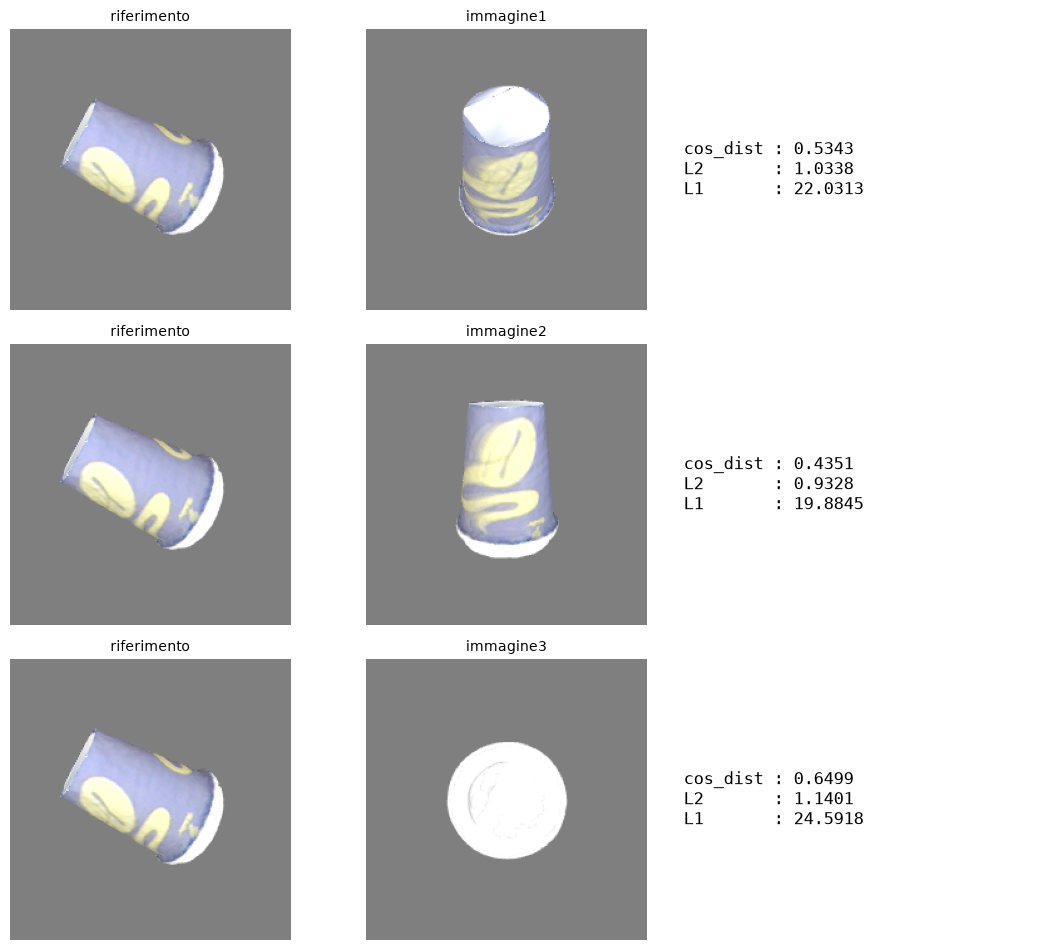

: 

In [ ]:
def plot_comparisons(ref_img, others, labels, layers=[-1], token="cls"):
    """
    Per ogni confronto mostra: [ref | altra | metriche].
      ref_img : immagine di riferimento (PIL)
      others  : lista di immagini PIL da confrontare con ref
      labels  : lista di etichette (es. ["vicinissima", "vicina", "lontana"])
    """
    n = len(others)
    fig, axes = plt.subplots(n, 3, figsize=(11, 3.2 * n))
    if n == 1:
        axes = axes[None, :]          # uniforma la forma quando c'è un solo confronto

    for row, (img, lab) in enumerate(zip(others, labels)):
        d = compare(ref_img, img, layers=layers, token=token)

        axes[row, 0].imshow(ref_img)
        axes[row, 0].set_title("riferimento", fontsize=10)
        axes[row, 0].axis("off")

        axes[row, 1].imshow(img)
        axes[row, 1].set_title(lab, fontsize=10)
        axes[row, 1].axis("off")

        txt = (f"cos_dist : {d['cos_dist']:.4f}\n"
               f"L2       : {d['l2']:.4f}\n"
               f"L1       : {d['l1']:.4f}")
        axes[row, 2].text(0.0, 0.5, txt, fontsize=12, family="monospace",
                          va="center", ha="left")
        axes[row, 2].axis("off")

    plt.tight_layout()
    plt.show()


# --- uso: ordina dal più vicino al più lontano ---
plot_comparisons(
    ref_img = img0,
    others  = [img_nearer, img_near, img_far],
    labels  = ["immagine1", "immagine2", "immagine3"],
)

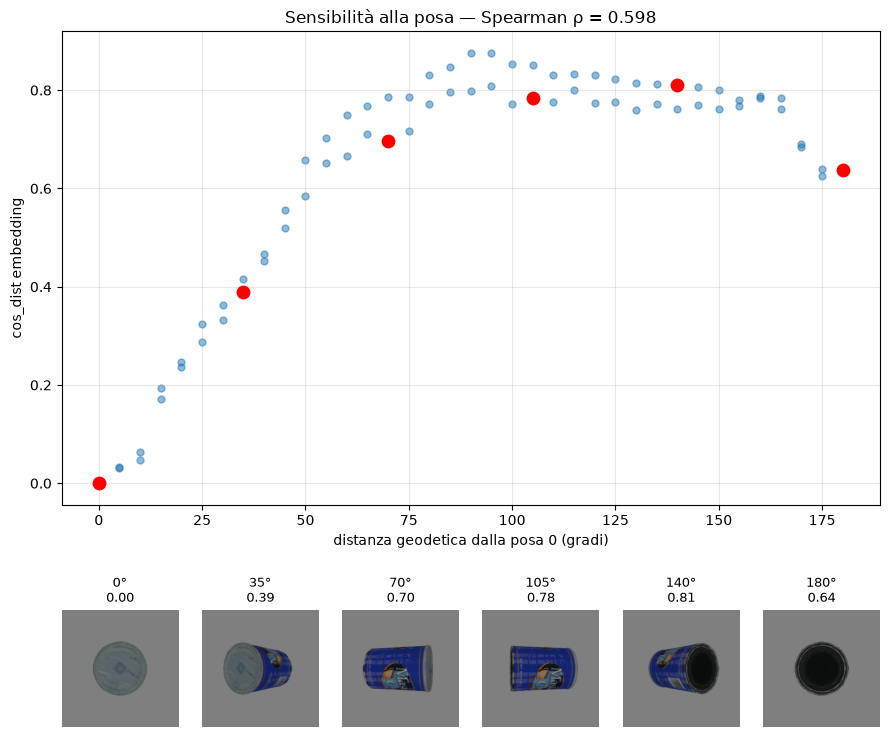

In [13]:
import pandas as pd
from scipy.spatial.transform import Rotation
from scipy.stats import spearmanr

# 1. leggi il CSV
csv_path = RENDERS / "ycbv" / "gt_poses.csv"
df = pd.read_csv(csv_path)
df = df[df["object"] == "obj_000001"].reset_index(drop=True)   # un oggetto solo

# 2. ricostruisci le rotazioni dalle 9 colonne r00..r22
r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))

# 3. posa di riferimento = la prima riga
R_ref = R_all[0]
ref_img = Image.open(RENDERS / df.loc[0, "image"]).convert("RGB")
e_ref = extract_features(ref_img, layers=[-1], token="cls")

# 4. per ogni posa: angolo geodetico (gradi) + cos_dist dell'embedding
angles, cos_dists = [], []
for i in range(len(df)):
    ang = (R_ref.inv() * R_all[i]).magnitude() * 180 / np.pi   # geodetica in gradi
    img = Image.open(RENDERS / df.loc[i, "image"]).convert("RGB")
    e = extract_features(img, layers=[-1], token="cls")
    cos_dists.append(1.0 - F.cosine_similarity(e_ref, e, dim=0).item())
    angles.append(ang)

angles, cos_dists = np.array(angles), np.array(cos_dists)

# ordina le pose per angolo geodetico crescente
order = np.argsort(angles)
# scegli 6 pose equispaziate lungo l'asse degli angoli (dalla più vicina alla più lontana)
sel = order[np.linspace(0, len(order) - 1, 6).astype(int)]

fig, axes = plt.subplots(2, 1, figsize=(9, 8), gridspec_kw={"height_ratios": [3, 1.4]})

# --- pannello alto: lo scatter, con evidenziate le pose mostrate sotto ---
axes[0].scatter(angles, cos_dists, s=25, alpha=0.5)
axes[0].scatter(angles[sel], cos_dists[sel], s=80, color="red", zorder=5)
axes[0].set_xlabel("distanza geodetica dalla posa 0 (gradi)")
axes[0].set_ylabel("cos_dist embedding")
axes[0].set_title(f"Sensibilità alla posa — Spearman ρ = {rho:.3f}")
axes[0].grid(alpha=0.3)

# --- pannello basso: le 6 viste corrispondenti (in rosso sopra) ---
gs = axes[1].get_subplotspec().subgridspec(1, 6)
axes[1].remove()
for k, idx in enumerate(sel):
    ax = fig.add_subplot(gs[0, k])
    img = Image.open(RENDERS / df.loc[idx, "image"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{angles[idx]:.0f}°\n{cos_dists[idx]:.2f}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

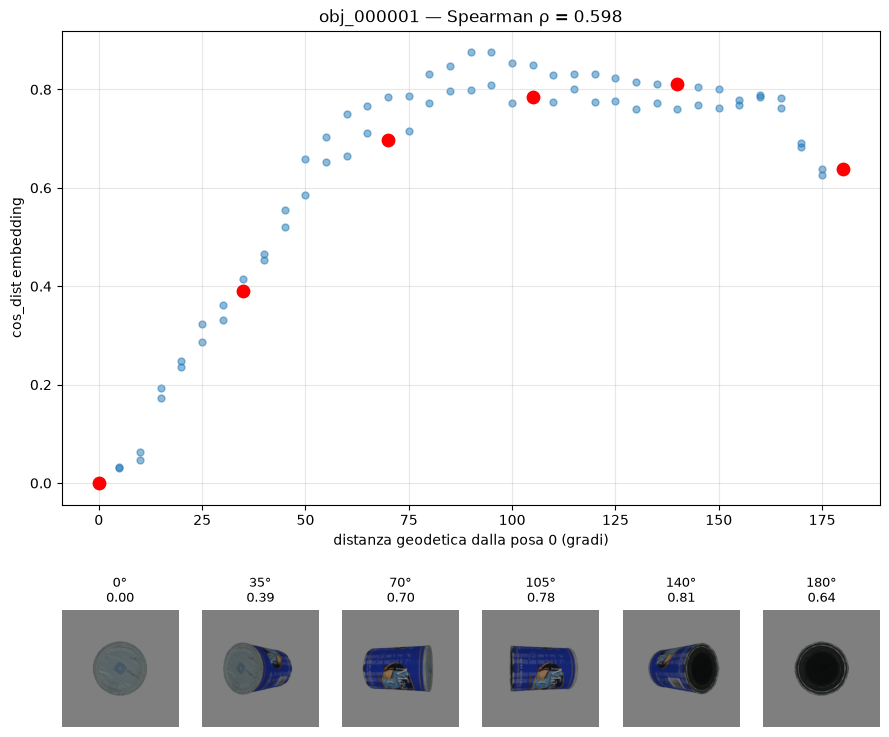

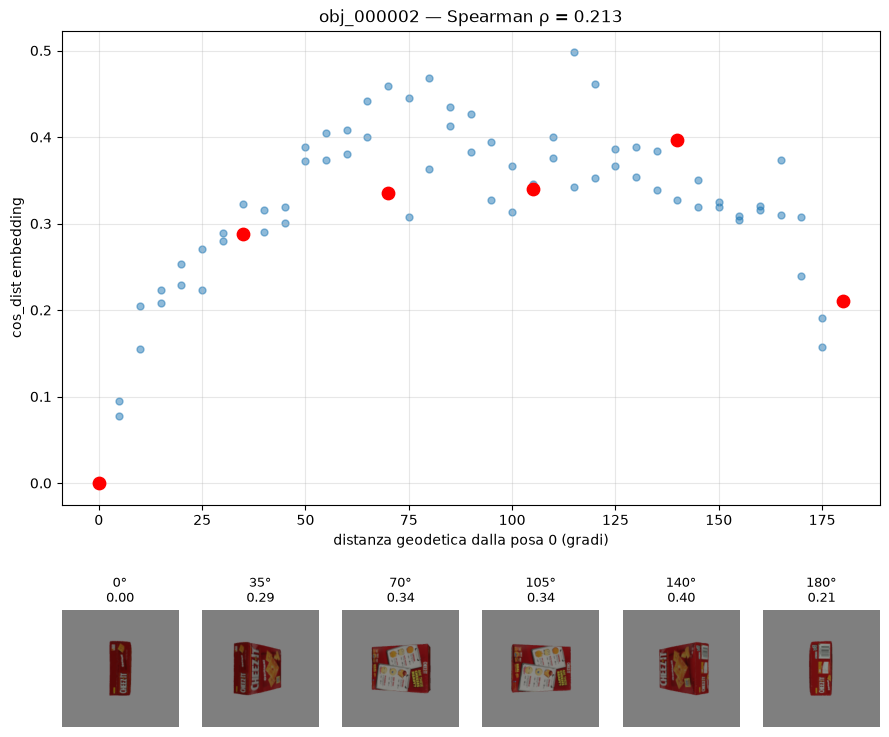

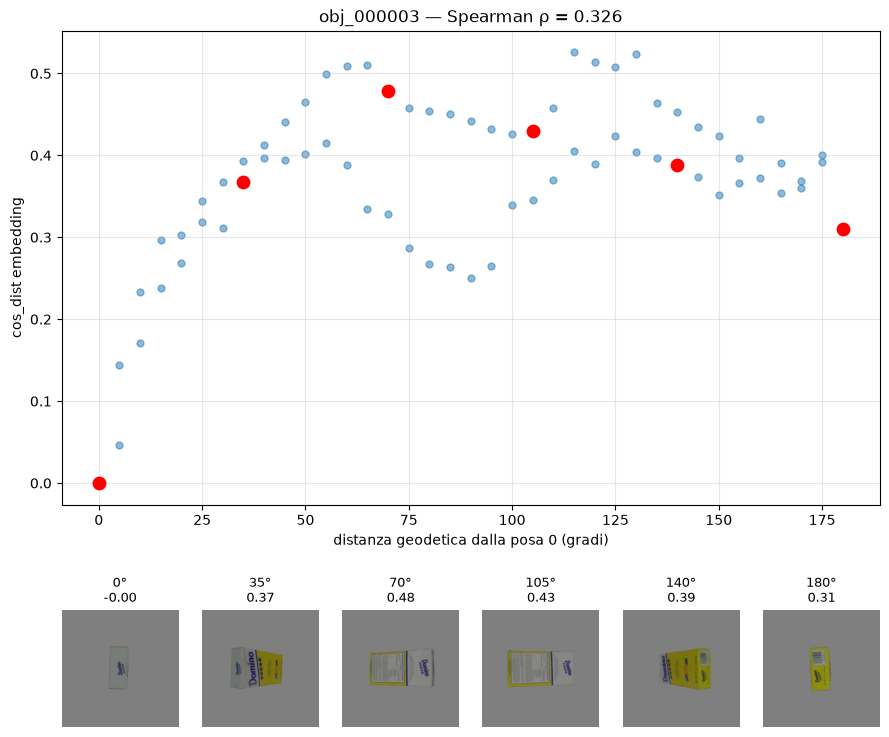

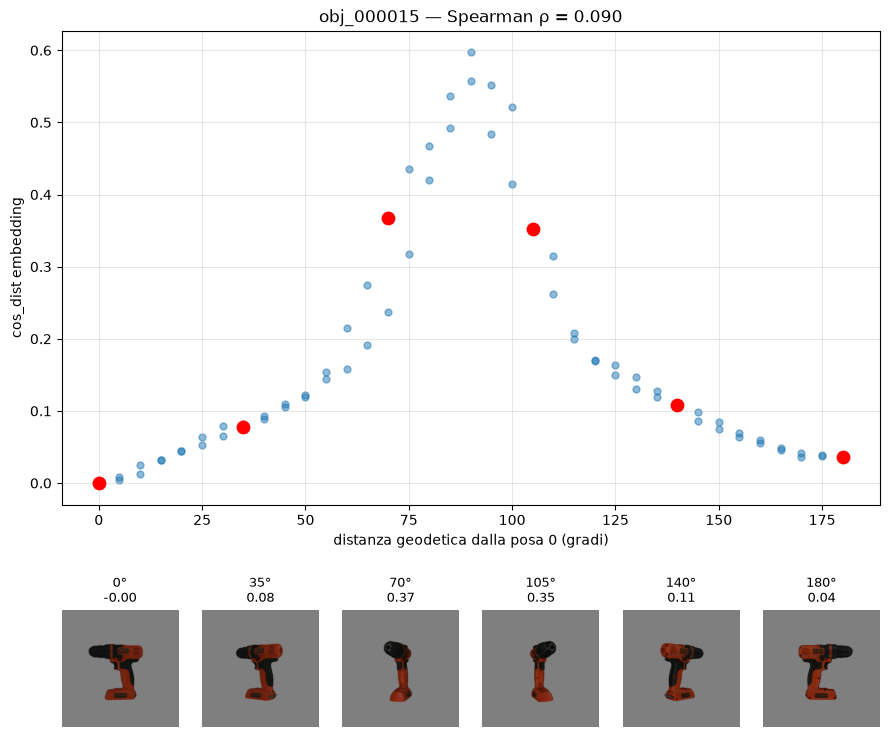

In [14]:
import pandas as pd
from scipy.spatial.transform import Rotation
from scipy.stats import spearmanr

def plot_object(obj_name, dataset="ycbv", layers=[-1], token="cls"):
    # 1. leggi il CSV e filtra l'oggetto
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    assert len(df) > 0, f"nessuna riga per {obj_name}"

    # 2. ricostruisci le rotazioni
    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))

    # 3. riferimento = prima riga
    R_ref = R_all[0]
    e_ref = extract_features(Image.open(RENDERS / df.loc[0, "image"]).convert("RGB"),
                             layers=layers, token=token)

    # 4. angoli + cos_dist
    angles, cos_dists = [], []
    for i in range(len(df)):
        ang = (R_ref.inv() * R_all[i]).magnitude() * 180 / np.pi
        e = extract_features(Image.open(RENDERS / df.loc[i, "image"]).convert("RGB"),
                             layers=layers, token=token)
        cos_dists.append(1.0 - F.cosine_similarity(e_ref, e, dim=0).item())
        angles.append(ang)
    angles, cos_dists = np.array(angles), np.array(cos_dists)
    rho, _ = spearmanr(angles, cos_dists)

    # 6 viste equispaziate lungo l'asse degli angoli
    order = np.argsort(angles)
    sel = order[np.linspace(0, len(order) - 1, 6).astype(int)]

    # --- figura: scatter sopra + 6 viste sotto ---
    fig, axes = plt.subplots(2, 1, figsize=(9, 8),
                             gridspec_kw={"height_ratios": [3, 1.4]})
    axes[0].scatter(angles, cos_dists, s=25, alpha=0.5)
    axes[0].scatter(angles[sel], cos_dists[sel], s=80, color="red", zorder=5)
    axes[0].set_xlabel("distanza geodetica dalla posa 0 (gradi)")
    axes[0].set_ylabel("cos_dist embedding")
    axes[0].set_title(f"{obj_name} — Spearman ρ = {rho:.3f}")
    axes[0].grid(alpha=0.3)

    gs = axes[1].get_subplotspec().subgridspec(1, 6)
    axes[1].remove()
    for k, idx in enumerate(sel):
        ax = fig.add_subplot(gs[0, k])
        ax.imshow(Image.open(RENDERS / df.loc[idx, "image"]).convert("RGB"))
        ax.set_title(f"{angles[idx]:.0f}°\n{cos_dists[idx]:.2f}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


# --- chiama la funzione per ogni oggetto: una figura completa a testa ---
OBJECTS = ["obj_000001", "obj_000002", "obj_000003", "obj_000015"]   # metti i tuoi
for obj in OBJECTS:
    plot_object(obj)